<a href="https://colab.research.google.com/github/MOHAMEDAAKIFASRAR/TSA_EXP10/blob/main/TSA_EXP10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

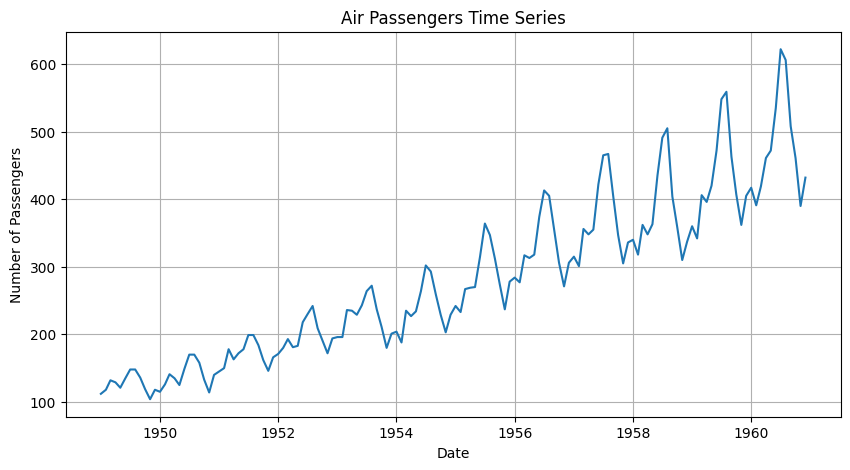

ADF Statistic: 0.8153688792060498
p-value: 0.991880243437641
Critical Values:
	1%: -3.4816817173418295
	5%: -2.8840418343195267
	10%: -2.578770059171598


/tmp/ipykernel_1018/882544536.py:49: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(timeseries)


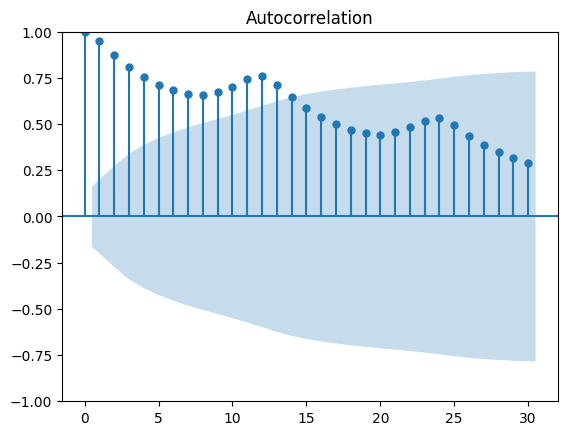

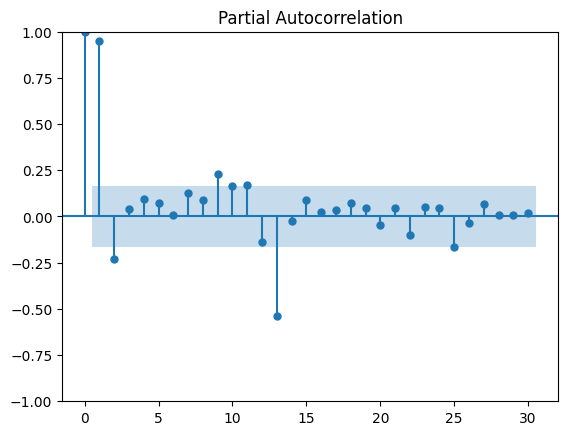

RMSE: 30.142008134932393


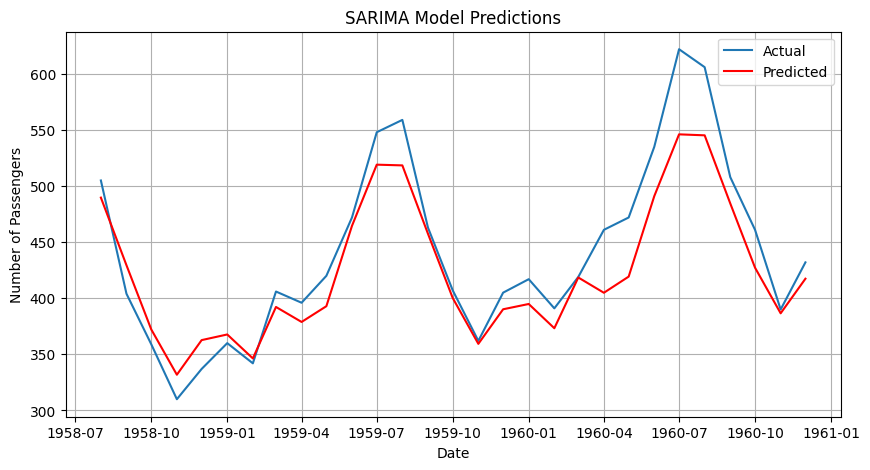

In [ ]:

# Import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error


# Load AirPassengers dataset
data = pd.read_csv('/content/AirPassengers.csv')

# Convert Month column to datetime
data['Month'] = pd.to_datetime(data['Month'], format='%Y-%m')

# Set Month column as index
data.set_index('Month', inplace=True)
data.sort_index(inplace=True)

# Extract passenger data
data = data['#Passengers'].asfreq('MS')


# ---------------------------------
# 1. AIR PASSENGER TIME SERIES
# ---------------------------------

plt.figure(figsize=(10, 5))

plt.plot(data.index, data)

plt.xlabel('Date')
plt.ylabel('Number of Passengers')
plt.title('Air Passengers Time Series')

plt.grid()
plt.show()


# ---------------------------------
# 2. CHECK STATIONARITY
# ---------------------------------

def check_stationarity(timeseries):

    result = adfuller(timeseries)

    print('ADF Statistic:', result[0])
    print('p-value:', result[1])

    print('Critical Values:')

    for key, value in result[4].items():
        print('\t{}: {}'.format(key, value))


check_stationarity(data)


# ---------------------------------
# 3. ACF PLOT
# ---------------------------------

plot_acf(data, lags=30)

plt.show()


# ---------------------------------
# 4. PACF PLOT
# ---------------------------------

plot_pacf(data, lags=30, method='ywm')

plt.show()


# ---------------------------------
# SPLIT TRAIN AND TEST DATA
# ---------------------------------

train_size = int(len(data) * 0.8)

train = data.iloc[:train_size]
test = data.iloc[train_size:]


# ---------------------------------
# BUILD SARIMA MODEL
# ---------------------------------

sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12)
)

sarima_result = sarima_model.fit(disp=False)


# ---------------------------------
# MAKE PREDICTIONS
# ---------------------------------

predictions = sarima_result.forecast(
    steps=len(test)
)


# ---------------------------------
# CALCULATE RMSE
# ---------------------------------

mse = mean_squared_error(test, predictions)

rmse = np.sqrt(mse)

print('RMSE:', rmse)


# ---------------------------------
# 5. ACTUAL VS PREDICTED GRAPH
# ---------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    test.index,
    test,
    label='Actual'
)

plt.plot(
    test.index,
    predictions,
    color='red',
    label='Predicted'
)

plt.xlabel('Date')
plt.ylabel('Number of Passengers')

plt.title('SARIMA Model Predictions')

plt.legend()
plt.grid()

plt.show()
